1. Chargement du data

In [1]:
!pip -q install kagglehub

In [2]:
import kagglehub
import os

data_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)
print(os.listdir(data_path))

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
['chest_xray']


In [3]:
for root , dirs , files in os.walk(data_path) :
  print(root, len(files))

/kaggle/input/chest-xray-pneumonia 0
/kaggle/input/chest-xray-pneumonia/chest_xray 0
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray 1
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val 1
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA 9
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL 9
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test 1
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/PNEUMONIA 390
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/NORMAL 234
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train 1
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train/PNEUMONIA 3876
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train/NORMAL 1342
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX 1
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray 3
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/val 1
/kaggle/input/chest-xr

In [4]:
from PIL import Image

if not os.path.isdir(os.path.join(data_path, "train")):
    data_path = os.path.join(data_path, "chest_xray")

folder = os.path.join(data_path, "train","NORMAL")

image_name = os.listdir(folder)[0]
image_path = os.path.join(folder,image_name)

img = Image.open(image_path)

print(img.size)
print(img.mode)


(1336, 1128)
L


Redimensionnement d'une image


(180, 180)
RGB


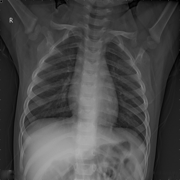

In [5]:
img_rgb = img.convert("RGB")
img_resized = img_rgb.resize((180, 180))

print(img_resized.size)
print(img_resized.mode)

display(img_resized)

Visualiser un échantillon d'images de chaque classe

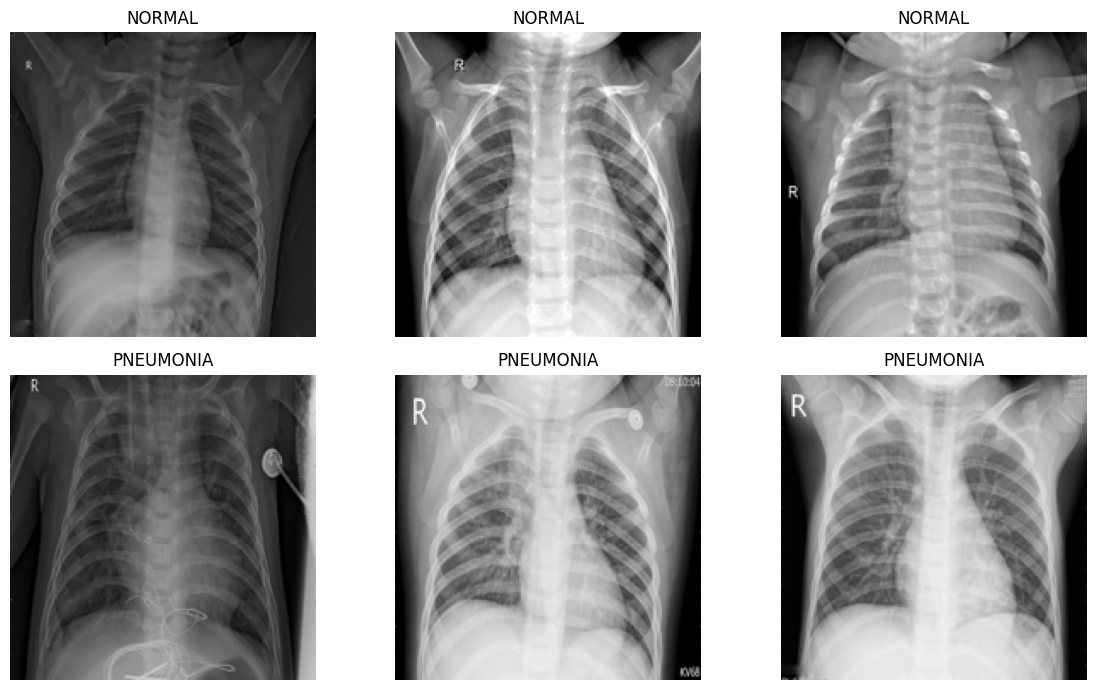

In [6]:
import matplotlib.pyplot as plt

fig,axes = plt.subplots(2 , 3, figsize=(12,7))

for i , category in enumerate(["NORMAL", "PNEUMONIA"]) :
  folder = os.path.join(data_path,"train",category)

  image_names = [
      name for name in os.listdir(folder)
      if name.lower().endswith((".jpg", ".jpeg", ".png"))
  ][:3]

  for j ,image_name in enumerate(image_names) :
    image_path = os.path.join(folder , image_name)

    with Image.open(image_path) as img :
      img_rgb = img.convert("RGB")
      img_resized = img_rgb.resize((180,180))

      axes[i,j].imshow(img_resized)
      axes[i,j].set_title(category)
      axes[i,j].axis("off")

plt.tight_layout()
plt.show()


Afficher graphiquement la distribution des classes

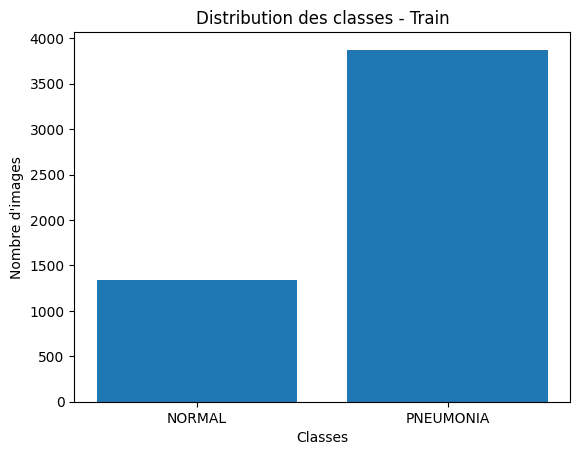

In [7]:
classes = ["NORMAL", "PNEUMONIA"]

counts =[
    len([
        f for f in os.listdir(os.path.join(data_path, "train", c))
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    for c in classes
]

plt.bar(classes, counts)
plt.title("Distribution des classes - Train")
plt.xlabel("Classes")
plt.ylabel("Nombre d'images")
plt.show()

Vérification des images manquantes, corrompues et invalides

In [8]:
corrupted =[]

for split in ["train","val","test"] :
  for category in ["NORMAL", "PNEUMONIA"] :
    folder = os.path.join(data_path , split , category)

    for filename in os.listdir(folder):
      if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

      path = os.path.join(folder,filename)

      try :
        with Image.open(path) as img :
          img.load()
      except Exception :
        corrupted.append(path)


print("Images corrompues :", len(corrupted))

Images corrompues : 0


Resize (180 × 180) + RGB

In [9]:
import numpy as np

def Load_images(folder):
  images = []
  labels = []

  for label , category in enumerate(["NORMAL", "PNEUMONIA"]):
    category_path = os.path.join(folder, category)

    for filename in os.listdir(category_path) :
      if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

      image_path = os.path.join(category_path , filename)

      with Image.open(image_path) as img :
        img = img.convert("RGB")
        img = img.resize((180,180))

        images.append(np.array(img))
        labels.append(label)

  return np.array(images, dtype=np.uint8), np.array(labels)




Chargement des images et encodage des labels

In [10]:
train_path = os.path.join(data_path,"train")

X,y = Load_images(train_path)


print("Train images :", X.shape)
print("Train labels :", y.shape)
print("Classes :", np.unique(y, return_counts=True))

Train images : (5216, 180, 180, 3)
Train labels : (5216,)
Classes : (array([0, 1]), array([1341, 3875]))


Séparation stratifiée Train / Validation

In [11]:
test_path = os.path.join(data_path, 'test')
val_path = os.path.join(data_path,'val')

X_test,y_test = Load_images(test_path)
X_val,y_val = Load_images(val_path)

print("Test images :", X_test.shape)
print("Test labels :", y_test.shape)

print("Val images :", X_val.shape)
print("Val labels :", y_val.shape)

Test images : (624, 180, 180, 3)
Test labels : (624,)
Val images : (16, 180, 180, 3)
Val labels : (16,)


In [12]:
print("Test path :", test_path)
print("Val path :", val_path)

print("Test NORMAL :", len(os.listdir(os.path.join(test_path, "NORMAL"))))
print("Test PNEUMONIA :", len(os.listdir(os.path.join(test_path, "PNEUMONIA"))))

Test path : /kaggle/input/chest-xray-pneumonia/chest_xray/test
Val path : /kaggle/input/chest-xray-pneumonia/chest_xray/val
Test NORMAL : 234
Test PNEUMONIA : 390


In [13]:
print("Train :", X.shape, y.shape)
print("Test :", X_test.shape, y_test.shape)
print("Validation :", X_val.shape, y_val.shape)

Train : (5216, 180, 180, 3) (5216,)
Test : (624, 180, 180, 3) (624,)
Validation : (16, 180, 180, 3) (16,)


Séparation stratifiée Train / Validation

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train : (4172, 180, 180, 3) (4172,)
Validation : (1044, 180, 180, 3) (1044,)
Test : (624, 180, 180, 3) (624,)


Normalisation des pixels entre 0 et 1

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train : (4172, 180, 180, 3) (4172,)
Validation : (1044, 180, 180, 3) (1044,)
Test : (624, 180, 180, 3) (624,)


In [16]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0

In [17]:
print("Min :", X_train.min())
print("Max :", X_train.max())
print("Type :", X_train.dtype)

Min : 0.0
Max : 1.0
Type : float32


In [18]:
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.05),
    tf.keras.layers.RandomTranslation(0.03, 0.03)
])

Construire notre CNN

In [22]:
import tensorflow as tf
from tensorflow.keras import layers,models

model = models.Sequential([
    layers.Input(shape=(180,180,3)),

    data_augmentation,

    layers.Conv2D(32,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1,activation="sigmoid")

])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

Compilation du CNN

In [23]:
model.compile(
    optimizer ="adam",
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

Early stopping

In [25]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor = "val_loss",
    patience = 3,
    restore_best_weights = True
)

Entraînement du CNN

In [ ]:
history = model.fit(
    X_train , y_train,
    validation_data = (X_val,y_val),
    epochs = 10,
    batch_size = 32,
    callbacks = [early_stopping]
)

Epoch 1/10
 76/131 ━━━━━━━━━━━━━━━━━━━━ 1:35 2s/step - accuracy: 0.7095 - loss: 0.6629